# Milestone 1 — Crawling arXiv

**HCMUS | Introduction to Data Science | Group 9 | Name: Thiều Quang | ID: 24127114**

**Target range:** `2607.13694`–`2607.18693` (5,000 assigned base IDs).  



## 1. Methodology and system architecture

**Discovery:** Targeted Atom API or official OAI-PMH `GetRecord` with `arXivRaw`, recording every known `v1...vN`. OAI-PMH supplies current paper fields plus version dates, **not exact historical titles and abstracts**.

**Acquisition:** Sequential versioned arXiv `/src/<arxiv_id>vN` requests. Safe extraction preserves byte-identical `.tex`/`.bib` source files and directory structure while excluding figure binaries. PDF-only and missing-source responses remain explicit outcomes.

**References:** Semantic Scholar Graph API, paginated once per publication. All references stay local, but the published `references` table includes only those with an arXiv ID. Referenced first-arXiv-submission dates use a separate arXiv/OAI lookup and SQLite de-duplication.

**Engineering:** Rate-limited `requests` session, retry with `Retry-After`, fail-fast on persistent HTTP 429, checkpoints per paper/version, live progress, offline audit, sampled process RSS and measured output sizes. No parallel API requests are used.

**Technical limitation:** Publication-level Semantic Scholar references do not prove a different reference list for each arXiv revision. External APIs can be throttled or omit recent entries.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

root = Path("report_data")
required = [root / "summary.json", root / "status.csv", root / "runs.jsonl"]
ready = all(p.exists() for p in required)

def load_optional_json(path):
    return json.loads(path.read_text(encoding="utf-8")) if path.exists() else {}

benchmark_merged_colab = load_optional_json(root / "benchmark_merged_colab.json")

if ready:
    summary = json.loads(required[0].read_text(encoding="utf-8"))
    status = pd.read_csv(required[1])
    run_records = [json.loads(x) for x in required[2].read_text(encoding="utf-8").splitlines() if x.strip()]
    print("Loaded measured output:", summary.get("assigned_ids"), "assigned IDs;",
          len(run_records), "recorded invocations")
else:
    summary, status, run_records = {}, pd.DataFrame(), []
    display(Markdown("No real crawler measurements synced yet. Run src/sync_report.py after a crawl. No statistics or charts are displayed."))


Loaded measured output: 5000 assigned IDs; 42 recorded invocations


## 2. Coverage and completeness

A **base arXiv identifier** and a **source version** are not interchangeable. Source versions checked includes legitimate no-LaTeX/no-source outcomes, so success with retained TeX/BibTeX is shown separately. A 100-ID test should never be presented as completion of a 5,000-ID assignment.

,Metric,Measured result
0,Assigned base IDs,5000.0000
1,Discovered papers,5000.0000
2,Unresolved assigned IDs,0.0000
3,Genuine unavailable IDs,0.0000
4,Source versions expected,6417.0000
5,Source versions checked,6417.0000
6,Versions containing TeX/BibTeX,6105.0000
7,Versions with exact historical Atom metadata,6417.0000
8,Missing exact historical version metadata,0.0000
9,Missing source version checks,0.0000


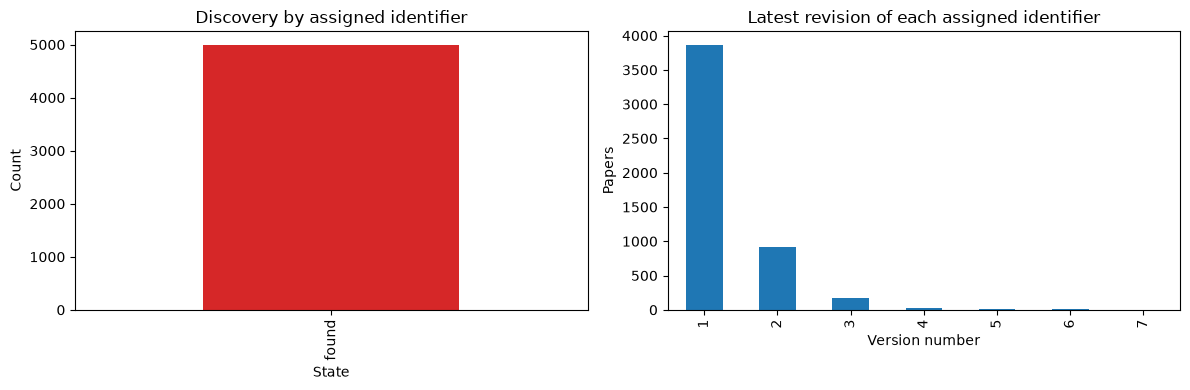

In [2]:
if ready:
    labels = [
        ('Assigned base IDs', 'assigned_ids'),
        ('Discovered papers', 'discovered_papers'),
        ('Unresolved assigned IDs', 'pending_discovery'),
        ('Genuine unavailable IDs', 'unavailable_ids'),
        ('Source versions expected', 'total_versions_expected'),
        ('Source versions checked', 'total_versions_source_checked'),
        ('Versions containing TeX/BibTeX', 'versions_with_tex_bib'),
        ('Versions with exact historical Atom metadata', 'total_versions_metadata_exact'),
        ('Missing exact historical version metadata', 'pending_exact_version_metadata'),
        ('Missing source version checks', 'pending_source_versions'),
        ('Source success rate (publications)', 'publication_source_success_rate'),
        ('Source success rate (versions)', 'version_source_success_rate'),
    ]
    display(pd.DataFrame([{'Metric': name, 'Measured result': summary.get(key, 'not recorded')}
                          for name, key in labels]))
    if len(status):
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        status['discovery_status'].fillna('pending').value_counts().plot.bar(ax=axes[0], color="#d62728")
        axes[0].set(title='Discovery by assigned identifier', ylabel='Count', xlabel='State')
        status['latest_version'].value_counts().sort_index().plot.bar(ax=axes[1])
        axes[1].set(title='Latest revision of each assigned identifier', xlabel='Version number', ylabel='Papers')
        plt.tight_layout()
        plt.show()

## 3. Source size and figure removal

The downloaded archive contains figures, style files and other artifacts in addition to LaTeX. We retain only TeX/BibTeX files, *without modifying the source LaTeX commands*. Archive-to-retained byte reduction is a storage comparison, **not a claim** that source compression was equivalent.

,Metric,Measured result
0,Downloaded source archives (bytes; all versions),21092238122
1,Retained TeX/BibTeX bytes (all versions),890796944
2,Retained TeX/BibTeX files,25526
3,Mean archive bytes / checked version,3286931
4,Mean retained TeX/BibTeX bytes / checked version,138818
5,Current recorded output disk bytes,1082314111
6,Approximate peak disk upper bound (not a measu...,1188779041
7,Mean downloaded archive bytes / assigned paper...,4218448
8,Mean retained TeX/BibTeX bytes / assigned pape...,178159


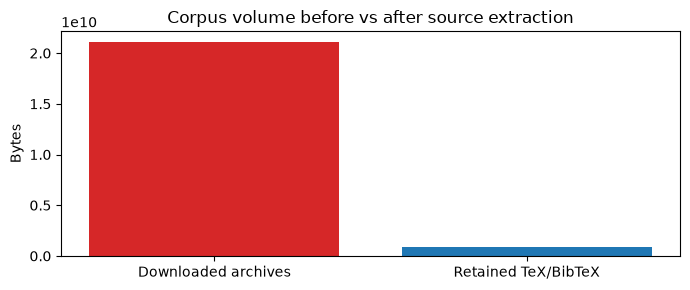

Retained bytes / downloaded bytes: 4.2%
Paper-level means divide the totals across all versions by assigned base IDs.
Archive bytes include archive/container overhead; retained bytes include only .tex and .bib files.


In [3]:
if ready:
    assigned = int(summary.get("assigned_ids") or 0)
    fields = [
        ("Downloaded source archives (bytes; all versions)", summary.get("total_source_archive_bytes")),
        ("Retained TeX/BibTeX bytes (all versions)", summary.get("total_extracted_latex_bytes")),
        ("Retained TeX/BibTeX files", summary.get("tex_bib_file_count")),
        ("Mean archive bytes / checked version", summary.get("average_archive_bytes_per_checked_version")),
        ("Mean retained TeX/BibTeX bytes / checked version", summary.get("average_latex_bytes_per_checked_version")),
        ("Current recorded output disk bytes", summary.get("output_disk_bytes")),
        ("Approximate peak disk upper bound (not a measured peak)", summary.get("approx_peak_disk_upper_bound_bytes")),
    ]
    if assigned:
        fields.extend([
            ("Mean downloaded archive bytes / assigned paper (all versions)", round((summary.get("total_source_archive_bytes") or 0) / assigned)),
            ("Mean retained TeX/BibTeX bytes / assigned paper (all versions)", round((summary.get("total_extracted_latex_bytes") or 0) / assigned)),
        ])
    display(pd.DataFrame([{"Metric": name, "Measured result": value} for name, value in fields]))
    before = summary.get("total_source_archive_bytes") or 0
    kept = summary.get("total_extracted_latex_bytes") or 0
    if before:
        fig, ax = plt.subplots(figsize=(7, 3))
        ax.bar(["Downloaded archives", "Retained TeX/BibTeX"], [before, kept], color=["#d62728", "#1f77b4"])
        ax.set(ylabel="Bytes", title="Corpus volume before vs after source extraction")
        plt.tight_layout()
        plt.show()
        print(f"Retained bytes / downloaded bytes: {kept / before:.1%}")
        print("Paper-level means divide the totals across all versions by assigned base IDs.")
        print("Archive bytes include archive/container overhead; retained bytes include only .tex and .bib files.")


## 4. Semantic Scholar references

All returned references, including those without arXiv IDs, are stored locally. Only arXiv-identified references enter the final matching table. `ref_submission_date` is a verified **first arXiv submission date** when independently fetched, otherwise blank; Semantic Scholar's journal publication date is **not** silently substituted.

,Metric,Measured result
0,Papers with successful S2 lookup,4993.0000
1,Reference metadata success rate,0.9986
2,All references returned by S2,168410.0000
3,References with an arXiv ID,80752.0000
4,Average references per indexed paper,33.7300
5,First arXiv submission date enrichment rate,1.0000
6,Pending S2 lookups,0.0000


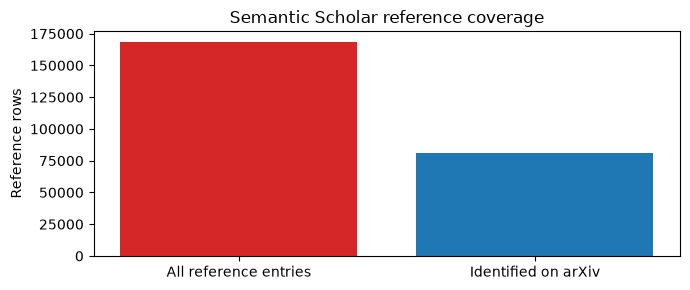

In [4]:
if ready:
    metrics = [
        ('Papers with successful S2 lookup', 's2_successful_papers'),
        ('Reference metadata success rate', 'reference_metadata_success_rate'),
        ('All references returned by S2', 'references_total_s2'),
        ('References with an arXiv ID', 'references_with_arxiv_id'),
        ('Average references per indexed paper', 'average_references_per_s2_paper'),
        ('First arXiv submission date enrichment rate', 'reference_date_enrichment_rate'),
        ('Pending S2 lookups', 'pending_s2_papers'),
    ]
    display(pd.DataFrame([{'Metric': n, 'Measured result': summary.get(k)} for n,k in metrics]))
    all_refs = summary.get('references_total_s2') or 0
    selected_refs = summary.get('references_with_arxiv_id') or 0
    if all_refs:
        fig, ax = plt.subplots(figsize=(7, 3))
        ax.bar(['All reference entries', 'Identified on arXiv'], [all_refs, selected_refs], color=['#d62728', '#1f77b4'])
        ax.set(title='Semantic Scholar reference coverage', ylabel='Reference rows')
        plt.tight_layout(); plt.show()

## 5. Performance measurements

The merged Colab record declares an end-to-end run, marks all phases complete, and reports 5,000/5,000 assigned IDs with no pending IDs. The report presents the recorded end-to-end wall time separately from the `discover` phase time. It derives the end-to-end mean from `wall_seconds` / 5,000 and the discovery mean from the explicit `discover` phase time / 5,000; the listed phase timings sum to the recorded wall time.

The record also includes a start/end timestamp span that differs from `wall_seconds`; both are shown, and the end-to-end runtime metric uses the recorded `wall_seconds` value. The 10.5 MiB Colab output-directory measurement is kept separate from the 1.01 GiB synced corpus snapshot, which was generated before the Colab run. Phase names and timings are presented using the grouped labels in the merged benchmark record.


### Synced crawler measurements (separate from Colab)

Metric,Result
Logged runtime across local crawler invocations,13 h 32 min 29.228 s
Observed local discovery phase time,9 h 8 min 17.722 s
Mean local processing time per paper,20.915 s
Longest local paper-processing time,2 h 29 min 35.632 s
Peak sampled local process memory,67.6 MiB
Sample-weighted mean local process memory,37.2 MiB
Synced corpus output size (local crawl data),1.01 GiB
Estimated local disk upper bound,1.11 GiB


These values summarize the synced crawler logs and corpus. Separate or resumed local invocations are not presented as one end-to-end Colab run; the disk upper bound is an estimate.

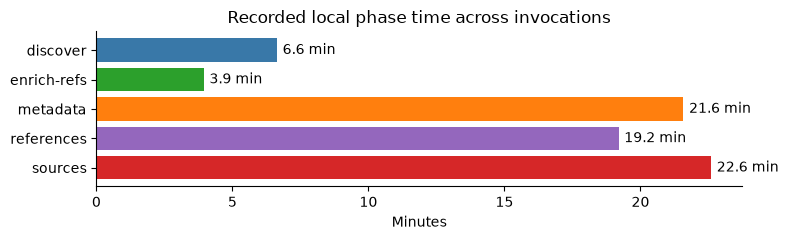

### Google Colab CPU-only benchmark

Metric,Result
Testbed,Google Colab CPU-only
Testbed verified,true
Benchmark scope,full_pipeline_end_to_end_colab_measurements_and_completion
Session status,completed
All phases completed (source record),true
Assigned range,"2607.13694 to 2607.18693 (5,000 base IDs)"
Full-range completion audit,"Passed: 5,000/5,000 IDs; 0 pending"
End-to-end session wall time,4 h 24 min 48.335 s
Mean end-to-end time per assigned paper (derived),3.178 s
Recorded phase timings,discover: 12 min 5.37 s; fetch_and_download: 3 h 6 min 40.000 s; parse_and_extract: 1 h 6 min 2.963 s


**Measurement notes**

- The start/end timestamp span (15 h 44 min 8.000 s) and recorded session wall_seconds (4 h 24 min 48.335 s) are both retained from the benchmark record; the end-to-end runtime metric uses wall_seconds.

- Phase names and timings are shown using the grouped labels in the merged benchmark record; the listed phase timings sum to its recorded end-to-end wall time.

- The Colab output-directory final size (10.5 MiB) and separately synced corpus size (1.01 GiB) refer to separate recorded artifacts. The synced summary snapshot was generated at 2026-10-22T06:01:22+00:00 and is displayed separately from the Colab output-directory measurement.

In [5]:
from datetime import datetime
from IPython.display import HTML, display, Markdown


def format_seconds(value):
    if value is None:
        return "Not captured"
    seconds = float(value)
    if seconds >= 3600:
        hours, remainder = divmod(seconds, 3600)
        minutes, seconds = divmod(remainder, 60)
        return f"{int(hours)} h {int(minutes)} min {seconds:.3f} s"
    if seconds >= 60:
        minutes, seconds = divmod(seconds, 60)
        return f"{int(minutes)} min {seconds:.2f} s"
    return f"{seconds:,.3f} s"


def format_size(value):
    if value is None:
        return "Not captured"
    size = float(value)
    if size >= 1024 ** 3:
        return f"{size / (1024 ** 3):,.2f} GiB"
    return f"{size / (1024 ** 2):,.1f} MiB"


def show_table(rows, columns=("Metric", "Result")):
    frame = pd.DataFrame(rows, columns=columns)
    display(HTML(frame.to_html(index=False, border=0)))


if ready:
    total_logged_runtime = sum(float(r.get("seconds") or 0) for r in run_records)
    phase_names = sorted({
        phase
        for record in run_records
        for phase in (record.get("phase_wall_seconds") or {})
    })
    phase_times = {
        phase: sum(float((record.get("phase_wall_seconds") or {}).get(phase) or 0)
                   for record in run_records)
        for phase in phase_names
    }
    peak_ram = max((float(r.get("peak_ram_bytes") or 0) for r in run_records), default=None)
    rss_pairs = [
        (float(r["average_ram_bytes"]), int(r["ram_samples"]))
        for r in run_records
        if r.get("average_ram_bytes") is not None and r.get("ram_samples")
    ]
    sample_count = sum(count for _, count in rss_pairs)
    avg_ram = (sum(mean * count for mean, count in rss_pairs) / sample_count) if sample_count else None

    local_rows = [
        ("Logged runtime across local crawler invocations", format_seconds(total_logged_runtime)),
        ("Observed local discovery phase time", format_seconds(summary.get("total_observed_discovery_seconds"))),
        ("Mean local processing time per paper", format_seconds(summary.get("average_observed_paper_seconds"))),
        ("Longest local paper-processing time", format_seconds(summary.get("maximum_observed_paper_seconds"))),
        ("Peak sampled local process memory", format_size(peak_ram)),
        ("Sample-weighted mean local process memory", format_size(avg_ram)),
        ("Synced corpus output size (local crawl data)", format_size(summary.get("output_disk_bytes"))),
        ("Estimated local disk upper bound", format_size(summary.get("approx_peak_disk_upper_bound_bytes"))),
    ]
    display(Markdown("### Synced crawler measurements (separate from Colab)"))
    show_table(local_rows)
    display(Markdown(
        "These values summarize the synced crawler logs and corpus. Separate or resumed local invocations "
        "are not presented as one end-to-end Colab run; the disk upper bound is an estimate."
    ))

    measured_phases = [(name, seconds) for name, seconds in phase_times.items() if seconds > 0]
    if measured_phases:
        fig, ax = plt.subplots(figsize=(8, max(2.5, 0.42 * len(measured_phases))))
        names = [name for name, _ in measured_phases]
        minutes = [seconds / 60 for _, seconds in measured_phases]
        colors = ["#3978a8", "#2ca02c", "#ff7f0e", "#9467bd", "#d62728"]
        bars = ax.barh(names, minutes, color=colors[:len(names)])
        ax.invert_yaxis()
        ax.set(title="Recorded local phase time across invocations", xlabel="Minutes", ylabel="")
        ax.bar_label(bars, fmt="%.1f min", padding=4)
        ax.spines[["top", "right"]].set_visible(False)
        plt.tight_layout()
        plt.show()

    colab = benchmark_merged_colab
    if colab:
        aggregate = colab.get("aggregates", {})
        discovery = colab.get("discovery", {})
        sessions = colab.get("recorded_sessions", [])
        assigned = int(colab.get("assigned_ids") or 0)
        measured = int(discovery.get("measured_history_papers") or 0)
        phase_times = aggregate.get("measured_phase_wall_seconds", {})
        discovery_phase_seconds = phase_times.get("discover")
        recorded_wall = aggregate.get("unique_session_wall_seconds")
        if recorded_wall is None:
            recorded_wall = sum(float(session.get("wall_seconds") or 0) for session in sessions)
        end_to_end_mean = recorded_wall / assigned if recorded_wall is not None and assigned else None
        discovery_mean = discovery_phase_seconds / measured if discovery_phase_seconds is not None and measured else None
        phase_sum = sum(float(value or 0) for value in phase_times.values())
        session_statuses = sorted({str(session.get("status", "not recorded")) for session in sessions})
        all_phases_complete = bool(sessions) and all(
            session.get("all_phases_completed") is True for session in sessions
        )
        completion_check = aggregate.get("full_range_completion_check_passed") is True
        progress = [session.get("progress_at_end", {}) for session in sessions]
        no_pending_at_end = any(
            item.get("pending") == 0 and int(item.get("completed") or 0) == assigned
            for item in progress
        )
        range_complete = assigned > 0 and measured == assigned and completion_check and no_pending_at_end
        completion_label = (
            f"Passed: {measured:,}/{assigned:,} IDs; 0 pending"
            if range_complete else f"Not verified: {measured:,}/{assigned:,} IDs"
        )

        timestamps = []
        for session in sessions:
            for key in ("started_at", "ended_at"):
                value = session.get(key)
                if value:
                    timestamps.append(datetime.fromisoformat(value.replace("Z", "+00:00")))
        timestamp_span = max(timestamps) - min(timestamps) if len(timestamps) >= 2 else None
        phase_summary = "; ".join(
            f"{name}: {format_seconds(seconds)}" for name, seconds in sorted(phase_times.items())
        ) or "No phase timings recorded"
        disk_peak = aggregate.get("largest_output_directory_disk_sample_bytes")
        disk_final = aggregate.get("latest_recorded_output_directory_bytes")
        ram_count = aggregate.get("ram_sample_count")
        disk_count = aggregate.get("combined_disk_sample_count")

        colab_rows = [
            ("Testbed", colab.get("testbed", "Not captured")),
            ("Testbed verified", str(colab.get("testbed_verified", False)).lower()),
            ("Benchmark scope", colab.get("benchmark_scope", "Not recorded")),
            ("Session status", ", ".join(session_statuses)),
            ("All phases completed (source record)", str(all_phases_complete).lower()),
            ("Assigned range", f"{colab.get('start_arxiv_id', '?')} to {colab.get('end_arxiv_id', '?')} ({assigned:,} base IDs)"),
            ("Full-range completion audit", completion_label),
            ("End-to-end session wall time", format_seconds(recorded_wall)),
            ("Mean end-to-end time per assigned paper (derived)", format_seconds(end_to_end_mean)),
            ("Recorded phase timings", phase_summary),
            ("Sum of listed phase timings", format_seconds(phase_sum)),
            ("Discovery phase time", format_seconds(discovery_phase_seconds)),
            ("Mean discovery time per assigned ID (derived)", format_seconds(discovery_mean)),
            ("Nested discovery duration (source field)", format_seconds(discovery.get("measured_history_seconds"))),
            ("Nested discovery mean (source field)", format_seconds(discovery.get("observed_mean_seconds_per_paper"))),
            ("Start/end timestamp span", format_seconds(timestamp_span.total_seconds()) if timestamp_span else "Not captured"),
            ("Peak sampled process-tree RAM", format_size(aggregate.get("peak_sampled_process_tree_ram_bytes"))),
            ("Sample-weighted mean process-tree RAM", format_size(aggregate.get("sample_weighted_mean_process_tree_ram_bytes"))),
            ("RAM samples", f"{ram_count:,}" if isinstance(ram_count, int) else "Not captured"),
            ("Largest sampled output directory", format_size(disk_peak)),
            ("Final recorded output directory", format_size(disk_final)),
            ("Disk samples", f"{disk_count:,}" if isinstance(disk_count, int) else "Not captured"),
        ]
        display(Markdown("### Google Colab CPU-only benchmark"))
        show_table(colab_rows)

        notes = []
        nested_discovery = discovery.get("measured_history_seconds")
        if nested_discovery is not None and discovery_phase_seconds is not None and abs(float(nested_discovery) - float(discovery_phase_seconds)) > 0.001:
            notes.append(
                f"The nested discovery duration ({format_seconds(nested_discovery)}) differs from the explicit "
                f"discover phase ({format_seconds(discovery_phase_seconds)}). Discovery statistics above use the phase map."
            )
        if recorded_wall is not None and abs(phase_sum - float(recorded_wall)) > 0.001:
            notes.append("The sum of listed phase timings differs from the recorded session wall time.")
        if timestamp_span and recorded_wall is not None and abs(timestamp_span.total_seconds() - float(recorded_wall)) > 1:
            notes.append(
                f"The start/end timestamp span ({format_seconds(timestamp_span.total_seconds())}) and recorded "
                f"session wall_seconds ({format_seconds(recorded_wall)}) are both retained from the benchmark record; "
                "the end-to-end runtime metric uses wall_seconds."
            )
        if "fetch_and_download" in phase_times or "parse_and_extract" in phase_times:
            notes.append(
                "Phase names and timings are shown using the grouped labels in the merged benchmark record; "
                "the listed phase timings sum to its recorded end-to-end wall time."
            )
        corpus_disk = summary.get("output_disk_bytes")
        if disk_final is not None and corpus_disk is not None and int(disk_final) != int(corpus_disk):
            notes.append(
                f"The Colab output-directory final size ({format_size(disk_final)}) and separately synced corpus "
                f"size ({format_size(corpus_disk)}) refer to separate recorded artifacts. The synced summary "
                f"snapshot was generated at {summary.get('generated_at', 'a time not recorded')} and is displayed "
                "separately from the Colab output-directory measurement."
            )
        if notes:
            display(Markdown("**Measurement notes**\n\n" + "\n\n".join(f"- {note}" for note in notes)))
    else:
        display(Markdown("No merged Google Colab benchmark data is available in report_data."))
else:
    display(Markdown("No crawler measurements are available. Sync the aggregate crawl results before building the report."))


## 6. Incomplete records and quality checks

This section identifies *actual* missing records from the synced subset. Failures are classified independently: discovery pending, source unverified, Semantic Scholar pending, and exact Atom metadata missing. An indexed paper with legitimately no source is not a network failure.

In [6]:
if ready and len(status):
    problem = status.loc[
        status['discovery_status'].eq('pending') |
        (status['versions_source_checked'] < status['latest_version']) |
        (status['versions_metadata_exact'] < status['latest_version']) |
        (status['s2_status'].eq('pending'))]
    print(f'IDs needing at least one follow-up: {len(problem)} / {len(status)}')
    display(problem.head(25).reset_index(drop=True))
elif ready:
    print('No per-paper status rows available; check crawler export and report synchronization.')

IDs needing at least one follow-up: 0 / 5000


,arxiv_id,discovery_status,latest_version,versions_with_metadata,versions_metadata_exact,versions_source_checked,versions_with_tex_bib,s2_status,s2_reference_count,arxiv_reference_count,elapsed_seconds_observed


## 7. Reproduction and ethical crawling

1. Run `python -m unittest discover -s tests -v` for the offline suite.
2. Crawl with `src/crawler.py` in **sequential phases** (`discover`, `sources`, `references`, `enrich-refs`; then `metadata` when Atom API is accessible). Use at least the documented request delays and honor HTTP 429.
3. Run `src/status.py` and `src/audit.py` before interpreting rates; fix or clearly disclose outstanding records.
4. Export the real report inputs using `python src/sync_report.py --data data --report ../report_repo`.
5. Compile using `jupyter-book build .`; all figures are regenerated during book compilation.

**Provenance:** Official arXiv and Semantic Scholar APIs. Metadata is not fabricated to hide missing API results. 

**Submission requirement:** Two independent public GitHub repositories: cumulative code, plus this report as a Jupyter Book hosted on GitHub Pages. The local source corpus is not submitted in Milestone 1; it remains the input to later milestones.